## Aim: Inspect Shedding Hub output used in Covasim

In [ ]:
import warnings
import shedding_hub as sh
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Catalog
catalog = sh.load_shedding_catalog()

print(f"{len(catalog.table)} fits over "
      f"{catalog.table.dataset_id.nunique()} datasets, "
      f"models {sorted(catalog.table.model.unique())}")

144 fits over 48 datasets, models ['exponential', 'gamma', 'gamma_shifted']


## Part 1 Inspect Shedding Hub

In [18]:
df_catalog = catalog.table[
    ["dataset_id", "biomarker", "specimen", "reference_event",
     "unit", "model", "n_subjects", "peak_day", "half_life_days"]
]

In [19]:
df_catalog.tail(15)

,dataset_id,biomarker,specimen,reference_event,unit,model,n_subjects,peak_day,half_life_days
129,vetter2020daily,SARS-CoV-2,oropharyngeal_swab,symptom onset,gc/mL,exponential,5,0.000000,1.117553
130,walsh2013viral,RSV,anterior_nares_swab+sputum,symptom onset,pfu/mL,exponential,22,0.000000,0.940437
131,walsh2013viral,RSV,anterior_nares_swab+sputum,symptom onset,pfu/mL,gamma,22,5.362475,0.627681
132,woelfel2020virological,SARS-CoV-2,stool,symptom onset,gc/mL,exponential,8,0.000000,1.573064
133,woelfel2020virological,SARS-CoV-2,stool,symptom onset,gc/mL,gamma,8,1.183731,1.231348
134,woelfel2020virological,SARS-CoV-2,sputum,symptom onset,gc/mL,exponential,9,0.000000,1.038280
135,woelfel2020virological,SARS-CoV-2,oropharyngeal_swab,symptom onset,gc/swab,exponential,9,0.000000,0.831295
136,xu2020characteristics,SARS-CoV-2,rectal_swab,hospital admission,gc/mL,exponential,7,0.000000,2.586078
137,xu2020characteristics,SARS-CoV-2,rectal_swab,hospital admission,gc/mL,gamma_shifted,7,5.281269,1.826963
138,xu2020characteristics,SARS-CoV-2,nasopharyngeal_swab,hospital admission,gc/mL,exponential,7,0.000000,0.323415


In [20]:
df_woelfel =  df_catalog[(df_catalog['dataset_id'] == 'woelfel2020virological') & (df_catalog['model'] == 'gamma')]

In [ ]:
df_woelfel =  df_catalog[(df_catalog['dataset_id'] == 'woelfel2020virological') & (df_catalog['model'] == 'gamma')]
df_woelfel.head(1)

,dataset_id,biomarker,specimen,reference_event,unit,model,n_subjects,peak_day,half_life_days
133,woelfel2020virological,SARS-CoV-2,stool,symptom onset,gc/mL,gamma,8,1.183731,1.231348


In [9]:
options = sh.shedding_options("SARS-CoV-2", "stool", catalog=catalog)
options

,biomarker,specimen,reference_event,event_class,unit,value_type,n_unit_studies,model,n_studies,n_subjects,n_measurements,rank
0,SARS-CoV-2,stool,symptom onset,landmark,gc/mL,concentration,4,gamma,2,16,118,1
1,SARS-CoV-2,stool,symptom onset,landmark,gc/mL,concentration,4,exponential,3,26,151,2
2,SARS-CoV-2,stool,symptom onset,landmark,gc/dry gram,concentration,2,gamma_shifted,1,29,281,3
3,SARS-CoV-2,stool,symptom onset,landmark,gc/dry gram,concentration,2,gamma,1,30,282,4
4,SARS-CoV-2,stool,symptom onset,landmark,gc/dry gram,concentration,2,exponential,1,35,297,5
5,SARS-CoV-2,stool,enrollment,administrative,gc/mL,concentration,4,gamma_shifted,1,45,296,6
6,SARS-CoV-2,stool,enrollment,administrative,gc/mL,concentration,4,gamma,1,42,272,7
7,SARS-CoV-2,stool,enrollment,administrative,gc/mL,concentration,4,exponential,1,76,476,8
8,SARS-CoV-2,stool,confirmation date,administrative,gc/dry gram,concentration,2,gamma,1,15,67,9
9,SARS-CoV-2,stool,confirmation date,administrative,gc/dry gram,concentration,2,exponential,1,16,69,10


In [10]:
source = sh.shedding_for("SARS-CoV-2", "stool", catalog=catalog)

print(source.selection)
print("\ncomponents:", len(source.fits))
print("study -> analyte:", source.selection.analytes)
print("weights:", source.weights.round(3).tolist())

picked symptom onset / gc/mL / gamma (2 study/studies, 16 subjects); its model resolves the rise

components: 2
study -> analyte: {'lui2020viral': '2019-nCoV_N1', 'woelfel2020virological': 'stool'}
weights: [0.5, 0.5]


## Part 2: Steps to get shedding 
- Source = woelfel2020virological

In [5]:
#Params
n_individuals = 50000
n_days = 180

In [11]:
50000*180

9000000

In [6]:
### Covasim wastewater
#Step 1
catalog = sh.load_shedding_catalog()

#Step 2
source = catalog.select(dataset_id="woelfel2020virological",
                                analyte="stool", model="gamma")

In [ ]:
#Step 3
shedding_df = sh.simulate_shedding(
            source, 
            n_individuals= n_individuals, 
            times=np.arange(1, n_days + 1),
            dispersion=0.1,  # Use a small dispersion to reduce variability
        )

## Additional
# Force integer types on time and individual_id to prevent pivot misalignment
shedding_df['time'] = shedding_df['time'].astype(int)
shedding_df['individual_id'] = shedding_df['individual_id'].astype(int)

In [10]:
shedding_df.shape

(9000000, 6)

In [9]:
shedding_df.tail(20)

,individual_id,time,log10_value,value,detected,source_dataset_id
8999980,49999,161.0,-32.768557,1.703894e-33,False,woelfel2020virological
8999981,49999,162.0,-33.012290,9.720981e-34,False,woelfel2020virological
8999982,49999,163.0,-33.256034,5.545818e-34,False,woelfel2020virological
8999983,49999,164.0,-33.499791,3.163802e-34,False,woelfel2020virological
8999984,49999,165.0,-33.743559,1.804850e-34,False,woelfel2020virological
8999985,49999,166.0,-33.987338,1.029584e-34,False,woelfel2020virological
8999986,49999,167.0,-34.231129,5.873143e-35,False,woelfel2020virological
8999987,49999,168.0,-34.474932,3.350181e-35,False,woelfel2020virological
8999988,49999,169.0,-34.718745,1.910974e-35,False,woelfel2020virological
8999989,49999,170.0,-34.962570,1.090009e-35,False,woelfel2020virological


In [ ]:
# 2. Pivot the EXACT same DataFrame
pivoted_df = shedding_df.pivot(
    index='individual_id', 
    columns='time', 
    values='value'
)
pivoted_df.head(10)

time,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,171.0,172.0,173.0,174.0,175.0,176.0,177.0,178.0,179.0,180.0
individual_id,,,,,,,,,,,,,,,,,,,,,
0,69268.238823,61248.992116,45397.101244,31302.647940,20746.345913,13409.963077,8519.401963,5344.386589,3320.407733,2047.272877,...,5.447131e-35,3.159646e-35,1.832737e-35,1.063048e-35,6.165904e-36,3.576284e-36,2.074238e-36,1.203031e-36,6.977284e-37,4.046577e-37
1,104427.470190,100976.521561,77631.468857,54335.253224,36123.014456,23246.347909,14627.612168,9054.287189,5534.563970,3349.748455,...,3.358825e-37,1.877853e-37,1.049842e-37,5.869146e-38,3.281061e-38,1.834182e-38,1.025320e-38,5.731462e-39,3.203763e-39,1.790790e-39
2,152636.140857,125867.919017,89363.350277,59674.122164,38532.534189,24358.118638,15173.772647,9351.551075,5716.296613,3471.670472,...,3.019154e-35,1.741070e-35,1.004014e-35,5.789693e-36,3.338596e-36,1.925151e-36,1.110091e-36,6.400960e-37,3.690834e-37,2.128123e-37
3,57040.444081,48851.048346,35184.326163,23606.398668,15234.786746,9593.342418,5939.339123,3631.744641,2199.758548,1322.472974,...,7.071599e-37,4.004119e-37,2.267188e-37,1.283688e-37,7.268127e-38,4.115069e-38,2.329825e-38,1.319050e-38,7.467767e-39,4.227778e-39
4,66868.621644,56660.909338,41085.570292,27950.885604,18362.171253,11799.190582,7467.157920,4673.145819,2899.744430,1787.263792,...,1.238955e-34,7.235653e-35,4.225635e-35,2.467734e-35,1.441109e-35,8.415652e-36,4.914406e-36,2.869768e-36,1.675773e-36,9.785347e-37
5,47824.714240,52984.448026,44210.811242,32847.499414,22901.099861,15336.994145,9990.062367,6376.347097,4007.154234,2487.618887,...,1.037309e-36,5.837964e-37,3.285491e-37,1.848948e-37,1.040483e-37,5.855062e-38,3.294686e-38,1.853886e-38,1.043130e-38,5.869220e-39
6,65179.944834,66132.633428,52101.330531,37008.307376,24837.145756,16081.027598,10157.039754,6300.075920,3853.984374,2332.006861,...,7.024864e-38,3.894452e-38,2.158947e-38,1.196809e-38,6.634297e-39,3.677500e-39,2.038440e-39,1.129877e-39,6.262567e-40,3.471056e-40
7,121436.685994,105030.563028,76679.901534,52229.281661,34247.996392,21923.630717,13803.290037,8585.736524,5291.069620,3236.914631,...,3.446028e-35,1.988123e-35,1.146988e-35,6.617075e-36,3.817374e-36,2.202191e-36,1.270390e-36,7.328432e-37,4.227435e-37,2.438567e-37
8,56425.084885,51099.113741,38147.664443,26313.440352,17380.738454,11170.055699,7044.139944,4381.150152,2696.225196,1645.515007,...,3.721210e-36,2.124260e-36,1.212610e-36,6.921893e-37,3.951109e-37,2.255297e-37,1.287297e-37,7.347588e-38,4.193740e-38,2.393586e-38


In [15]:
# 3. Reindex to guarantee complete mapping for all individuals and days
# Column 1 in pivoted_df -> Index 0 in NumPy array
all_individuals = np.arange(n_individuals)
all_times = np.arange(1, n_days + 1)
pivoted_df = pivoted_df.reindex(index=all_individuals, columns=all_times)
#pivoted_df = pivoted_df.fillna(0.0).to_numpy()
pivoted_df.head(10)

time,1,2,3,4,5,6,7,8,9,10,...,171,172,173,174,175,176,177,178,179,180
individual_id,,,,,,,,,,,,,,,,,,,,,
0,69268.238823,61248.992116,45397.101244,31302.647940,20746.345913,13409.963077,8519.401963,5344.386589,3320.407733,2047.272877,...,5.447131e-35,3.159646e-35,1.832737e-35,1.063048e-35,6.165904e-36,3.576284e-36,2.074238e-36,1.203031e-36,6.977284e-37,4.046577e-37
1,104427.470190,100976.521561,77631.468857,54335.253224,36123.014456,23246.347909,14627.612168,9054.287189,5534.563970,3349.748455,...,3.358825e-37,1.877853e-37,1.049842e-37,5.869146e-38,3.281061e-38,1.834182e-38,1.025320e-38,5.731462e-39,3.203763e-39,1.790790e-39
2,152636.140857,125867.919017,89363.350277,59674.122164,38532.534189,24358.118638,15173.772647,9351.551075,5716.296613,3471.670472,...,3.019154e-35,1.741070e-35,1.004014e-35,5.789693e-36,3.338596e-36,1.925151e-36,1.110091e-36,6.400960e-37,3.690834e-37,2.128123e-37
3,57040.444081,48851.048346,35184.326163,23606.398668,15234.786746,9593.342418,5939.339123,3631.744641,2199.758548,1322.472974,...,7.071599e-37,4.004119e-37,2.267188e-37,1.283688e-37,7.268127e-38,4.115069e-38,2.329825e-38,1.319050e-38,7.467767e-39,4.227778e-39
4,66868.621644,56660.909338,41085.570292,27950.885604,18362.171253,11799.190582,7467.157920,4673.145819,2899.744430,1787.263792,...,1.238955e-34,7.235653e-35,4.225635e-35,2.467734e-35,1.441109e-35,8.415652e-36,4.914406e-36,2.869768e-36,1.675773e-36,9.785347e-37
5,47824.714240,52984.448026,44210.811242,32847.499414,22901.099861,15336.994145,9990.062367,6376.347097,4007.154234,2487.618887,...,1.037309e-36,5.837964e-37,3.285491e-37,1.848948e-37,1.040483e-37,5.855062e-38,3.294686e-38,1.853886e-38,1.043130e-38,5.869220e-39
6,65179.944834,66132.633428,52101.330531,37008.307376,24837.145756,16081.027598,10157.039754,6300.075920,3853.984374,2332.006861,...,7.024864e-38,3.894452e-38,2.158947e-38,1.196809e-38,6.634297e-39,3.677500e-39,2.038440e-39,1.129877e-39,6.262567e-40,3.471056e-40
7,121436.685994,105030.563028,76679.901534,52229.281661,34247.996392,21923.630717,13803.290037,8585.736524,5291.069620,3236.914631,...,3.446028e-35,1.988123e-35,1.146988e-35,6.617075e-36,3.817374e-36,2.202191e-36,1.270390e-36,7.328432e-37,4.227435e-37,2.438567e-37
8,56425.084885,51099.113741,38147.664443,26313.440352,17380.738454,11170.055699,7044.139944,4381.150152,2696.225196,1645.515007,...,3.721210e-36,2.124260e-36,1.212610e-36,6.921893e-37,3.951109e-37,2.255297e-37,1.287297e-37,7.347588e-38,4.193740e-38,2.393586e-38


## Plot

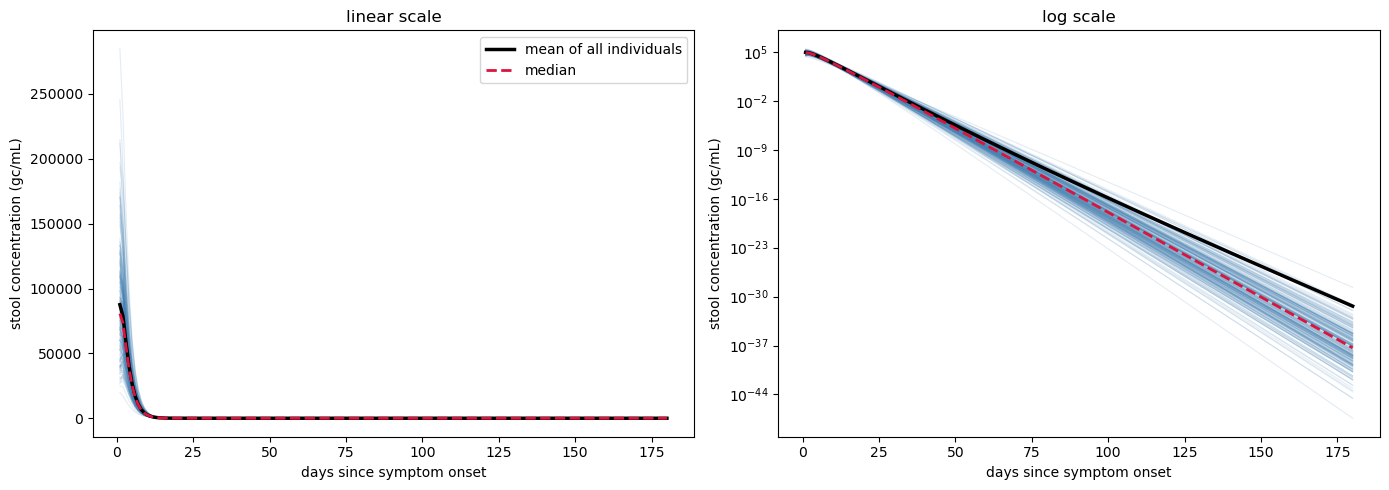

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

df = pivoted_df          # rows = individual_id, columns = time (1..180), values = gc/mL (keep the NaN version, before fillna)
days = df.columns.to_numpy()

rng = np.random.default_rng(0)
shown = rng.choice(df.index, size=min(len(df), 200), replace=False)   # plot at most 200 lines so it stays readable

fig, (ax_linear, ax_log) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, title in [(ax_linear, 'linear scale'), (ax_log, 'log scale')]:
    for i in shown:
        ax.plot(days, df.loc[i].to_numpy(), color='steelblue', alpha=0.15, linewidth=0.8)    # one line per individual
    ax.plot(days, df.mean(axis=0).to_numpy(), color='black', linewidth=2.5, label='mean of all individuals')
    ax.plot(days, df.median(axis=0).to_numpy(), color='crimson', linewidth=2, linestyle='--', label='median')
    ax.set_xlabel('days since symptom onset')
    ax.set_ylabel('stool concentration (gc/mL)')
    ax.set_title(title)
ax_log.set_yscale('log')
ax_linear.legend()
plt.tight_layout()
plt.show()

## Part 3b. Shedding-hub -> Covasim
- Smaller pop

### Covasim wastewater
#Step 1
catalog = sh.load_shedding_catalog()

#Step 2
source = catalog.select(dataset_id="woelfel2020virological",
                                analyte="stool", model="gamma")

In [ ]:
#Params
n_individuals = 50
n_days = 25


#Step 3
shedding_df2 = sh.simulate_shedding(
            source, 
            n_individuals= n_individuals, 
            times=np.arange(1, n_days + 1),
            dispersion=0.1,  # Use a small dispersion to reduce variability
        )

,individual_id,time,log10_value,value,detected,source_dataset_id
0,0,1.0,5.008259,101919.817391,True,woelfel2020virological
1,0,2.0,4.987108,97075.141517,True,woelfel2020virological
2,0,3.0,4.864369,73176.077555,True,woelfel2020virological
3,0,4.0,4.700038,50123.091854,True,woelfel2020virological
4,0,5.0,4.512916,32577.389921,True,woelfel2020virological
...,...,...,...,...,...,...
1245,49,21.0,0.599402,3.975596,False,woelfel2020virological
1246,49,22.0,0.361329,2.297887,False,woelfel2020virological
1247,49,23.0,0.122683,1.326426,False,woelfel2020virological
1248,49,24.0,-0.116486,0.764740,False,woelfel2020virological


In [29]:
## Additional
# Force integer types on time and individual_id to prevent pivot misalignment
shedding_df2['time'] = shedding_df2['time'].astype(int)
shedding_df2['individual_id'] = shedding_df2['individual_id'].astype(int)

shedding_df2

,individual_id,time,log10_value,value,detected,source_dataset_id
0,0,1,5.008259,101919.817391,True,woelfel2020virological
1,0,2,4.987108,97075.141517,True,woelfel2020virological
2,0,3,4.864369,73176.077555,True,woelfel2020virological
3,0,4,4.700038,50123.091854,True,woelfel2020virological
4,0,5,4.512916,32577.389921,True,woelfel2020virological
...,...,...,...,...,...,...
1245,49,21,0.599402,3.975596,False,woelfel2020virological
1246,49,22,0.361329,2.297887,False,woelfel2020virological
1247,49,23,0.122683,1.326426,False,woelfel2020virological
1248,49,24,-0.116486,0.764740,False,woelfel2020virological


In [30]:
# 2. Pivot the EXACT same DataFrame
pivoted_df2 = shedding_df2.pivot(
    index='individual_id', 
    columns='time', 
    values='value'
)
pivoted_df2.head(10)

time,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
individual_id,,,,,,,,,,,,,,,,,,,,,
0,101919.817391,97075.141517,73176.077555,50123.091854,32577.389921,20482.330596,12586.198028,7605.513172,4537.339912,2679.707434,...,99.664592,56.758317,32.232509,18.258585,10.319546,5.820632,3.277012,1.841856,1.033630,0.579243
1,83891.965597,76907.618255,58188.441624,40697.329713,27263.982258,17773.822546,11371.227710,7175.589556,4480.673781,2774.779810,...,140.455745,84.422552,50.625906,30.296411,18.096957,10.791814,6.425772,3.820822,2.269028,1.345920
2,130621.610133,122017.242609,91238.274020,62281.958508,40445.010580,25447.961341,15666.669721,9492.335444,5681.704108,3368.299110,...,128.980310,73.862820,42.185561,24.036059,13.665664,7.754562,4.392595,2.484220,1.402889,0.791176
3,36326.090676,36106.777353,29097.925723,21519.809425,15183.720025,10398.994577,6977.245260,4611.554754,3013.171910,1951.042651,...,127.754095,80.066660,50.053102,31.219894,19.433610,12.074882,7.490200,4.639264,2.869495,1.772604
4,138258.295695,130935.583449,100088.833997,70084.447198,46771.945082,30279.386384,19195.438391,11983.414118,7393.838551,4520.035256,...,209.088134,123.632690,72.914895,42.904167,25.193331,14.765977,8.639818,5.047520,2.944691,1.715692
5,50600.448432,52655.761826,42280.637012,30530.789137,20800.549100,13659.482481,8745.162604,5495.805416,3405.109290,2086.261348,...,95.351393,56.111970,32.917538,19.257030,11.237394,6.542778,3.801633,2.204798,1.276518,0.737912
6,61818.005344,58675.636733,45491.591508,32466.004485,22141.851631,14673.387060,9533.279127,6104.587134,3865.984539,2426.999008,...,132.555145,80.638411,48.936017,29.632691,17.908793,10.804308,6.507801,3.914171,2.351080,1.410471
7,61154.181792,49117.141918,35577.628295,24703.190248,16759.634148,11204.951382,7415.872737,4871.907721,3182.584458,2069.777075,...,147.739687,94.550625,60.435356,38.586529,24.612048,15.684455,9.987047,6.354512,4.040474,2.567505
8,90842.843521,88840.700329,68209.890336,47430.574136,31238.809461,19880.116007,12355.290541,7546.665479,4548.881271,2713.415782,...,106.647931,61.266468,35.093533,20.049437,11.427836,6.499971,3.690028,2.091185,1.183216,0.668499


In [31]:
all_individuals = np.arange(n_individuals)
all_individuals

all_times = np.arange(1, n_days + 1)
all_times

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25])

In [33]:
pivoted_df2 = pivoted_df2.reindex(index=all_individuals, columns=all_times)
pivoted_df2.head(10)

time,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
individual_id,,,,,,,,,,,,,,,,,,,,,
0,101919.817391,97075.141517,73176.077555,50123.091854,32577.389921,20482.330596,12586.198028,7605.513172,4537.339912,2679.707434,...,99.664592,56.758317,32.232509,18.258585,10.319546,5.820632,3.277012,1.841856,1.033630,0.579243
1,83891.965597,76907.618255,58188.441624,40697.329713,27263.982258,17773.822546,11371.227710,7175.589556,4480.673781,2774.779810,...,140.455745,84.422552,50.625906,30.296411,18.096957,10.791814,6.425772,3.820822,2.269028,1.345920
2,130621.610133,122017.242609,91238.274020,62281.958508,40445.010580,25447.961341,15666.669721,9492.335444,5681.704108,3368.299110,...,128.980310,73.862820,42.185561,24.036059,13.665664,7.754562,4.392595,2.484220,1.402889,0.791176
3,36326.090676,36106.777353,29097.925723,21519.809425,15183.720025,10398.994577,6977.245260,4611.554754,3013.171910,1951.042651,...,127.754095,80.066660,50.053102,31.219894,19.433610,12.074882,7.490200,4.639264,2.869495,1.772604
4,138258.295695,130935.583449,100088.833997,70084.447198,46771.945082,30279.386384,19195.438391,11983.414118,7393.838551,4520.035256,...,209.088134,123.632690,72.914895,42.904167,25.193331,14.765977,8.639818,5.047520,2.944691,1.715692
5,50600.448432,52655.761826,42280.637012,30530.789137,20800.549100,13659.482481,8745.162604,5495.805416,3405.109290,2086.261348,...,95.351393,56.111970,32.917538,19.257030,11.237394,6.542778,3.801633,2.204798,1.276518,0.737912
6,61818.005344,58675.636733,45491.591508,32466.004485,22141.851631,14673.387060,9533.279127,6104.587134,3865.984539,2426.999008,...,132.555145,80.638411,48.936017,29.632691,17.908793,10.804308,6.507801,3.914171,2.351080,1.410471
7,61154.181792,49117.141918,35577.628295,24703.190248,16759.634148,11204.951382,7415.872737,4871.907721,3182.584458,2069.777075,...,147.739687,94.550625,60.435356,38.586529,24.612048,15.684455,9.987047,6.354512,4.040474,2.567505
8,90842.843521,88840.700329,68209.890336,47430.574136,31238.809461,19880.116007,12355.290541,7546.665479,4548.881271,2713.415782,...,106.647931,61.266468,35.093533,20.049437,11.427836,6.499971,3.690028,2.091185,1.183216,0.668499


## Plot

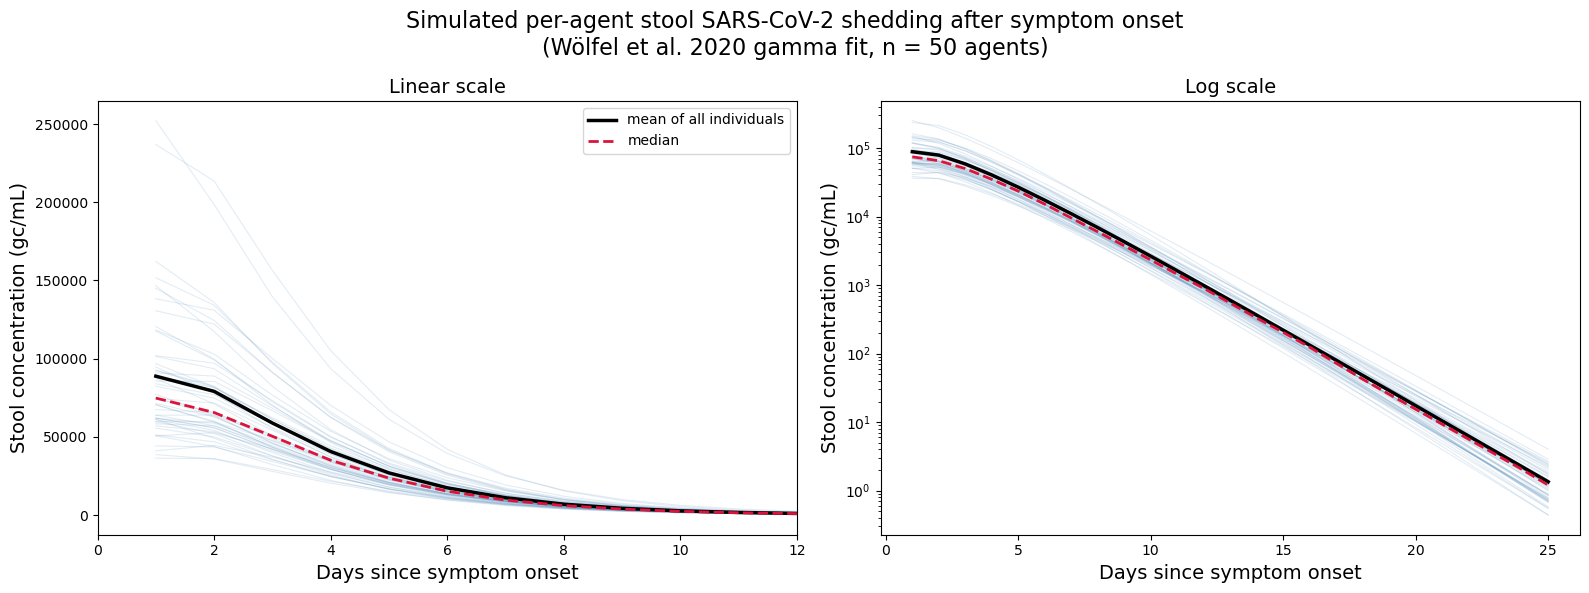

In [42]:
#Plot
df = pivoted_df2          # rows = individual_id, columns = time (1..180), values = gc/mL (keep the NaN version, before fillna)
days = df.columns.to_numpy()

rng = np.random.default_rng(0)
shown = rng.choice(df.index, size=min(len(df), 200), replace=False)   # plot at most 200 lines so it stays readable

fig, (ax_linear, ax_log) = plt.subplots(1, 2, figsize=(16, 6)) #, sharex=True)
for ax, title in [(ax_linear, 'Linear scale'), (ax_log, 'Log scale')]:
    for i in shown:
        ax.plot(days, df.loc[i].to_numpy(), color='steelblue', alpha=0.15, linewidth=0.8)    # one line per individual
    if title == 'Linear scale':
          ax_linear.set_xlim(0, 12)   
    ax.plot(days, df.mean(axis=0).to_numpy(), color='black', linewidth=2.5, label='mean of all individuals')
    ax.plot(days, df.median(axis=0).to_numpy(), color='crimson', linewidth=2, linestyle='--', label='median')
    ax.set_xlabel('Days since symptom onset', fontsize=14)
    ax.set_ylabel('Stool concentration (gc/mL)', fontsize=14)

fig.suptitle(
    f'Simulated per-agent stool SARS-CoV-2 shedding after symptom onset\n'
    f'(Wölfel et al. 2020 gamma fit, n = {n_individuals} agents)',
    fontsize=16,
)
ax_linear.set_title('Linear scale', fontsize=14)
ax_log.set_title('Log scale', fontsize=14)
plt.tight_layout()
ax_log.set_yscale('log')
ax_linear.legend()
plt.tight_layout()
plt.show()

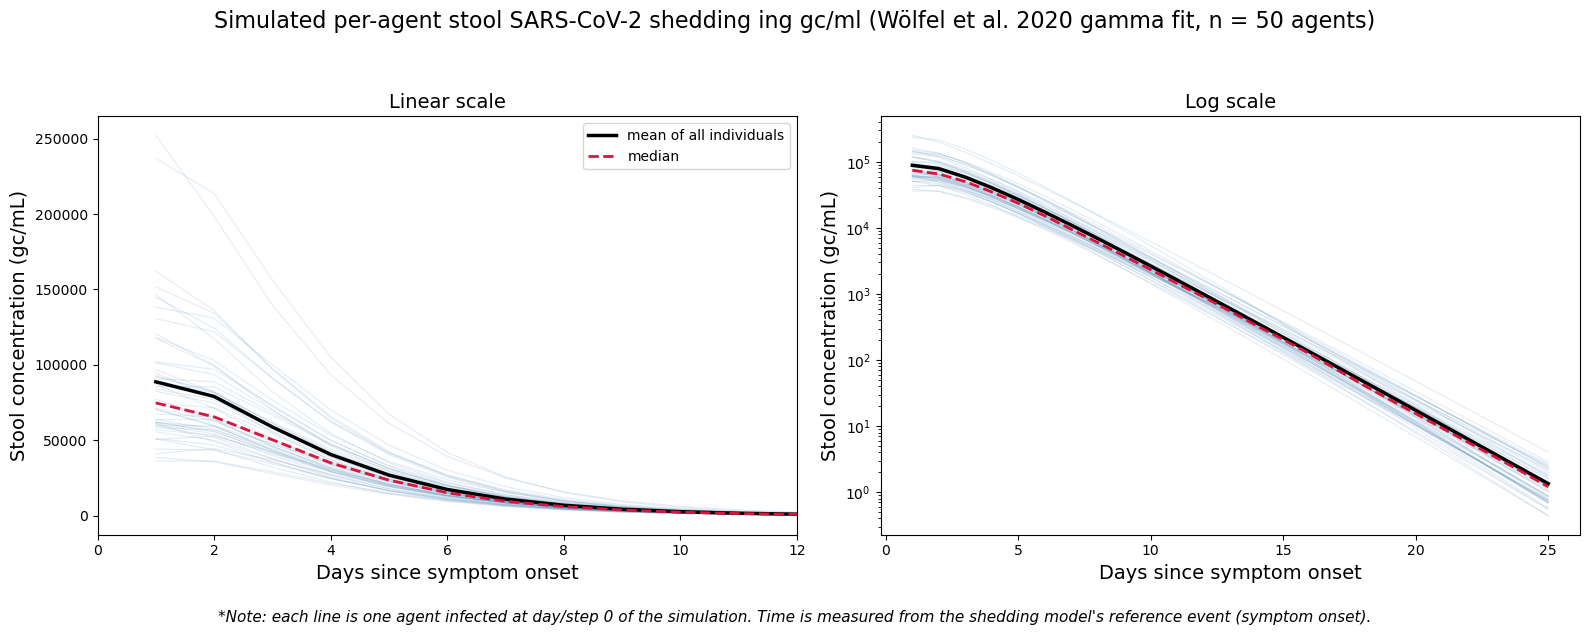

In [46]:
#Plot
df = pivoted_df2          # rows = individual_id, columns = time (1..180), values = gc/mL (keep the NaN version, before fillna)
days = df.columns.to_numpy()

rng = np.random.default_rng(0)
shown = rng.choice(df.index, size=min(len(df), 200), replace=False)   # plot at most 200 lines so it stays readable

fig, (ax_linear, ax_log) = plt.subplots(1, 2, figsize=(16, 6)) #, sharex=True)
for ax, title in [(ax_linear, 'Linear scale'), (ax_log, 'Log scale')]:
    for i in shown:
        ax.plot(days, df.loc[i].to_numpy(), color='steelblue', alpha=0.15, linewidth=0.8)    # one line per individual
    if title == 'Linear scale':
          ax_linear.set_xlim(0, 12)   
    ax.plot(days, df.mean(axis=0).to_numpy(), color='black', linewidth=2.5, label='mean of all individuals')
    ax.plot(days, df.median(axis=0).to_numpy(), color='crimson', linewidth=2, linestyle='--', label='median')
    ax.set_xlabel('Days since symptom onset', fontsize=14)
    ax.set_ylabel('Stool concentration (gc/mL)', fontsize=14)

fig.suptitle(
    f'Simulated per-agent stool SARS-CoV-2 shedding ing gc/ml (Wölfel et al. 2020 gamma fit, n = {n_individuals} agents)',
    fontsize=16,
)

fig.text(
    0.5, -0.02,
    '*Note: each line is one agent infected at day/step 0 of the simulation. '
    'Time is measured from the shedding model\'s reference event (symptom onset).',
    ha='center', va='top', fontsize=11, style='italic', wrap=True,
)

ax_linear.set_title('Linear scale', fontsize=14)
ax_log.set_title('Log scale', fontsize=14)
plt.tight_layout()
ax_log.set_yscale('log')
ax_linear.legend()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Function in sim.py Compute viral shedding

In [ ]:
def compute_viral_shedding_lookup(self):
        
        n_individuals = self['pop_size']
        n_days = self.pars['n_days']

        # Handle zero population size ---
        if n_individuals <= 0:
            # Pre-allocate an empty matrix with 0 rows and return early
            self.shedding_lookup = np.empty((0, n_days), dtype=float)
            return

        catalog = sh.load_shedding_catalog()
        source = catalog.select(dataset_id="woelfel2020virological",
                                analyte="stool", model="gamma"
)

        n_days = self.pars['n_days']
        n_individuals = self['pop_size']

        # 1. Run simulation ONCE
        shedding_df = sh.simulate_shedding(
            source, 
            n_individuals= n_individuals, 
            times=np.arange(1, n_days + 1),
            dispersion=0.1,  # Use a small dispersion to reduce variability
        )
        # Force integer types on time and individual_id to prevent pivot misalignment
        shedding_df['time'] = shedding_df['time'].astype(int)
        shedding_df['individual_id'] = shedding_df['individual_id'].astype(int)
        
        # 2. Pivot the EXACT same DataFrame
        pivoted_df = shedding_df.pivot(
            index='individual_id', 
            columns='time', 
            values='value'
        )
        # 3. Reindex to guarantee complete mapping for all individuals and days
        # Column 1 in pivoted_df -> Index 0 in NumPy array
        all_individuals = np.arange(n_individuals)
        all_times = np.arange(1, n_days + 1)
        
        pivoted_df = pivoted_df.reindex(index=all_individuals, columns=all_times)

        # 4. Store in lookup array
        self.shedding_lookup = pivoted_df.fillna(0.0).to_numpy()
        return

In [23]:
traj = sh.simulate_shedding(
    source,
    n_individuals=500,
    times=np.arange(1, 31),
    seed=42,
)
traj.head()

,individual_id,time,log10_value,value,detected,source_dataset_id
0,0,1.0,6.195276,1.567746e+06,True,woelfel2020virological
1,0,2.0,5.990994,9.794768e+05,True,woelfel2020virological
2,0,3.0,5.716516,5.206145e+05,True,woelfel2020virological
3,0,4.0,5.413298,2.589992e+05,True,woelfel2020virological
4,0,5.0,5.094333,1.242604e+05,True,woelfel2020virological


In [24]:
print("rows:", len(traj))
print("attrs:", {k: traj.attrs[k] for k in
                 ("time_origin", "reference_event_class", "unit", "model")})
print("\nagents per source study:")
print(traj.groupby("source_dataset_id").individual_id.nunique())

rows: 15000
attrs: {'time_origin': 'symptom onset', 'reference_event_class': 'landmark', 'unit': 'gc/mL', 'model': 'gamma'}

agents per source study:
source_dataset_id
lui2020viral              249
woelfel2020virological    251
Name: individual_id, dtype: int64


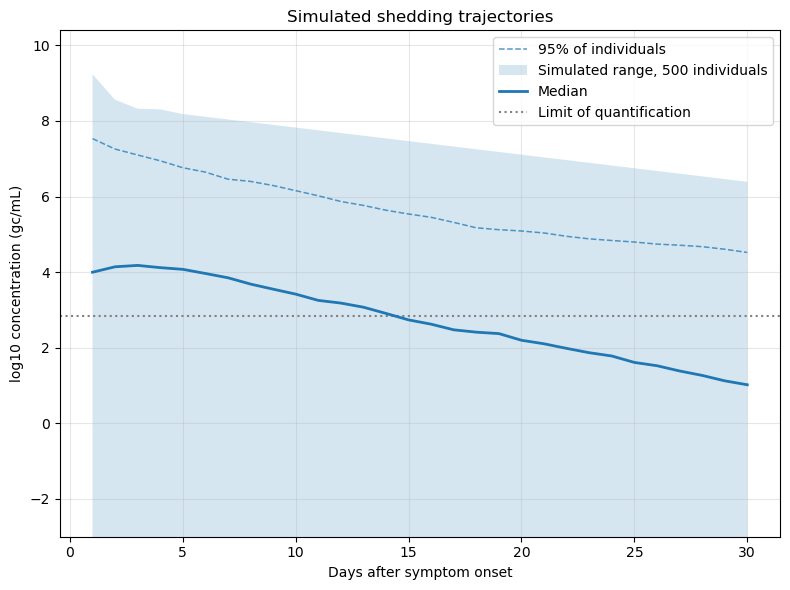

In [25]:
fig = sh.plot_simulated_shedding(traj, source=source)
fig  # ending the cell on the figure renders it